# Bulk scalar CLN, memory and actual CUDA

We compare complete three-stage CLN calculations for the same internal round wire, constant material and zero shift. The curved mesh has geometry order 3, p=2,3,4 and quadrature bonus 8. Every scalar, physical weak equation, divergence, curl fit, field and coefficient gate is retained. Original ICCG A-T and condensed A-T remain independent references.

See the [implementation and measurement protocol](BULK_SCALAR_CLN.md), [previous colored recovery](22_batched_scalar_cln.ipynb) and [scalar formulation limits](SCALAR_CLN.md). This is an iterative compatible local inverse, not a one-pass construction or a literal implementation of a verified higher-order theorem from Bíró.


**Selected GPU route: MATLAB mexcuda.** Full-CLN accuracy and process-tree
memory are validated on the upgraded 100 host. Formal speed acceptance is
pending an idle mdx host with a usable CUDA/MATLAB runtime. LAB timing tables
below are earlier exploratory observations, not formal performance acceptance.


In [1]:
import json, statistics
from pathlib import Path
from IPython.display import Markdown, display
import numpy as np
import matplotlib.pyplot as plt
base=Path('docs/data') if Path('docs/data').exists() else Path('data')
cpu,gpu,memory,controls=[json.loads((base/name).read_text()) for name in
    ('bulk_cln_study.json','gpu_cln_study.json','bulk_memory_study.json','bulk_controls.json')]
assert all(d['complete'] for d in (cpu,gpu,memory,controls))
display(Markdown('Runtime: `'+json.dumps(cpu['runtime'])+'`'))
def median(c,route):
    return statistics.median(r['seconds'] for r in c['repeats'] if r['route']==route and r['repeat']>0)
def table(header,rows):
    display(Markdown('| '+' | '.join(header)+' |\n|'+ '|'.join(['---']*len(header))+'|\n'+
                     '\n'.join('| '+' | '.join(map(str,r))+' |' for r in rows)))


Runtime: `{"host": "intel11", "python": "3.12.10", "ngsolve": "6.2.2607", "numpy": "2.5.2", "radia": "5.2.3", "threads": 4, "blas_pools": [{"user_api": "blas", "internal_api": "openblas", "num_threads": 1, "prefix": "libscipy_openblas", "version": "0.3.34.0.0", "threading_layer": "pthreads", "architecture": "SkylakeX"}, {"user_api": "blas", "internal_api": "mkl", "num_threads": 1, "prefix": "mkl_rt", "version": "2026.1-Product", "threading_layer": "intel"}, {"user_api": "blas", "internal_api": "openblas", "num_threads": 1, "prefix": "libscipy_openblas", "version": "0.3.30", "threading_layer": "pthreads", "architecture": "SkylakeX"}, {"user_api": "openmp", "internal_api": "openmp", "num_threads": 4, "prefix": "libiomp", "version": null}]}`

## Historical exploratory CPU timings

Each route has a first observation and three warmed observations in alternating route order. Setup, full scalar/local recursion and all residual checks are timed. Mesh generation and cross-route comparisons are outside the measured solve. Every raw observation remains in JSON; warm medians and ranges are shown below. Phase times are wall-clock observations, not estimates from Python profiler callback attribution.


| Cohort | original | condensed | scalar-batched | scalar-bulk | Colored/bulk |
|---|---|---|---|---|---|
| p=2, h=3 mm | 1.661 [1.417, 2.155] | 1.377 [0.571, 1.575] | 7.906 [2.880, 8.116] | 4.404 [1.895, 4.995] | 1.80x |
| p=3, h=3 mm | 2.048 [2.020, 2.077] | 1.522 [1.483, 1.553] | 8.287 [8.135, 8.322] | 5.315 [5.204, 5.334] | 1.56x |
| p=3, h=2 mm | 6.048 [6.030, 6.095] | 4.490 [4.489, 4.580] | 26.128 [25.761, 26.430] | 17.230 [17.108, 17.516] | 1.52x |
| p=4, h=3 mm | 6.550 [5.883, 6.898] | 3.502 [3.270, 3.584] | 19.726 [19.265, 20.455] | 13.173 [13.056, 13.464] | 1.50x |

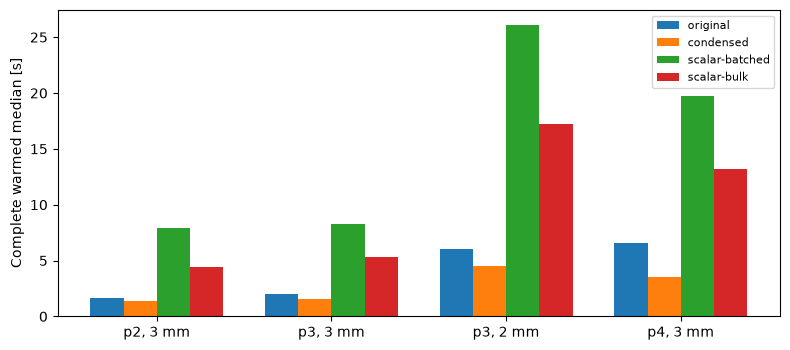

Bulk maxima: coefficient 1.211717e-10; volume vector field 5.365341e-09; recovered physical residual 4.199712e-10


| Cohort | Setup | Scalar solves | Target assembly | Projection iterations | Algebraic fit checks | Integrated curl checks | Weak equation checks |
|---|---|---|---|---|---|---|---|
| p2, 3 mm | 0.9647 | 0.6346 | 0.3161 | 1.0074 | 0.0726 | 0.2842 | 0.8460 |
| p3, 3 mm | 1.3552 | 0.8736 | 0.4197 | 1.0195 | 0.0632 | 0.2363 | 1.1333 |
| p3, 2 mm | 3.6984 | 2.4951 | 1.1900 | 5.2207 | 0.2892 | 0.6305 | 3.1844 |
| p4, 3 mm | 3.9754 | 1.9026 | 0.9761 | 2.8865 | 0.1753 | 0.3556 | 2.5793 |

In [2]:
routes=['original','condensed','scalar-batched','scalar-bulk']
rows=[]
for c in cpu['cohorts']:
    row=[f"p={c['order']}, h={c['maxh']*1000:g} mm"]
    for route in routes:
        warm=[r['seconds'] for r in c['repeats'] if r['route']==route and r['repeat']>0]
        row.append(f'{statistics.median(warm):.3f} [{min(warm):.3f}, {max(warm):.3f}]')
    row.append(f"{median(c,'scalar-batched')/median(c,'scalar-bulk'):.2f}x")
    rows.append(row)
table(['Cohort']+routes+['Colored/bulk'],rows)
fig,ax=plt.subplots(figsize=(8,3.6))
x=np.arange(4);width=.19
for j,route in enumerate(routes):
    ax.bar(x+(j-1.5)*width,[median(c,route) for c in cpu['cohorts']],width,label=route)
ax.set_xticks(x,[f"p{c['order']}, {c['maxh']*1000:g} mm" for c in cpu['cohorts']])
ax.set_ylabel('Complete warmed median [s]');ax.legend(fontsize=8);fig.tight_layout();plt.show()
coef=max(abs(v) for c in cpu['cohorts'] for r in c['comparisons'] if r['route']=='scalar-bulk' for v in r['relative_coefficients'])
field=max(v for c in cpu['cohorts'] for r in c['comparisons'] if r['route']=='scalar-bulk' for v in r['volume_relative_field_errors'])
res=max(s['recovered_original_residual'] for c in cpu['cohorts'] for r in c['repeats'] if r['route']=='scalar-bulk' for s in r['solves'])
print(f'Bulk maxima: coefficient {coef:.6e}; volume vector field {field:.6e}; recovered physical residual {res:.6e}')
table(['Cohort','Setup','Scalar solves','Target assembly','Projection iterations','Algebraic fit checks','Integrated curl checks','Weak equation checks'],[
    [f"p{c['order']}, {c['maxh']*1000:g} mm"]+[f'{statistics.median(values):.4f}' for values in
       [[r['setup_seconds'] for r in c['repeats'] if r['route']=='scalar-bulk' and r['repeat']>0]]+
       [[sum(s[key] for s in r['solves']) for r in c['repeats'] if r['route']=='scalar-bulk' and r['repeat']>0] for key in
        ('scalar_seconds','target_seconds','iteration_seconds','curl_check_seconds','field_check_seconds','physical_check_seconds')]]
    for c in cpu['cohorts']])


## Memory of the complete method

Element-by-element recovery avoids a global vector matrix/factor, but retains local dense operators and a global compatible coefficient vector. The scalar trace matrix/factor, checking spaces, field samples and temporary allocations also consume memory. Original A-T is iterative, so a hypothetical large vector Cholesky is not the comparison.

One fresh process per route/cohort records Windows lifetime peak working set and private commit. Identical imports/meshes, baseline and post-GC snapshots are saved. We report whole-process peaks, without subtracting unrelated peaks. Unique NumPy operator storage is a separate diagnostic and excludes native FE matrices/factors. These single-process observations establish bounded cases, not a memory scaling law.


In [3]:
rows=[]
for c in cpu['cohorts']:
    cases=[r for r in memory['cases'] if (r['order'],r['maxh'])==(c['order'],c['maxh'])]
    for r in cases:
        s=r['post_solve']
        rows.append([f"p{r['order']}, {r['maxh']*1000:g} mm",r['route'],
                     f"{r['import_baseline']['rss']/2**20:.1f}",f"{s['peak_wset']/2**20:.1f}",
                     f"{s['peak_pagefile']/2**20:.1f}",f"{sum(r['local_numpy_bytes_by_role'].values())/2**20:.1f}"])
table(['Cohort','Route','Import RSS MiB','Peak RSS MiB','Peak private commit MiB','NumPy local operators MiB'],rows)


| Cohort | Route | Import RSS MiB | Peak RSS MiB | Peak private commit MiB | NumPy local operators MiB |
|---|---|---|---|---|---|
| p2, 3 mm | original | 95.3 | 145.6 | 2120.1 | 0.0 |
| p2, 3 mm | condensed | 95.2 | 124.1 | 2108.8 | 0.0 |
| p2, 3 mm | scalar-batched | 95.2 | 137.6 | 2123.0 | 12.9 |
| p2, 3 mm | scalar-bulk | 95.1 | 135.8 | 2121.4 | 10.3 |
| p2, 3 mm | scalar-gpu | 95.2 | 421.3 | 2771.9 | 10.3 |
| p3, 3 mm | original | 95.1 | 203.8 | 2176.2 | 0.0 |
| p3, 3 mm | condensed | 95.0 | 170.7 | 2147.3 | 0.0 |
| p3, 3 mm | scalar-batched | 95.1 | 223.4 | 2208.7 | 59.6 |
| p3, 3 mm | scalar-bulk | 95.0 | 221.2 | 2197.3 | 47.4 |
| p3, 3 mm | scalar-gpu | 95.1 | 501.6 | 2871.5 | 47.4 |
| p3, 2 mm | original | 95.1 | 352.5 | 2323.3 | 0.0 |
| p3, 2 mm | condensed | 95.2 | 321.8 | 2298.6 | 0.0 |
| p3, 2 mm | scalar-batched | 95.0 | 462.6 | 2449.3 | 178.1 |
| p3, 2 mm | scalar-bulk | 95.2 | 462.6 | 2440.2 | 142.0 |
| p3, 2 mm | scalar-gpu | 95.2 | 728.5 | 3163.5 | 142.0 |
| p4, 3 mm | original | 94.9 | 387.8 | 2358.2 | 0.0 |
| p4, 3 mm | condensed | 95.1 | 280.9 | 2256.7 | 0.0 |
| p4, 3 mm | scalar-batched | 94.8 | 458.8 | 2440.1 | 199.5 |
| p4, 3 mm | scalar-bulk | 95.2 | 466.4 | 2439.9 | 158.5 |
| p4, 3 mm | scalar-gpu | 95.2 | 735.3 | 3175.6 | 158.5 |

## Preliminary CuPy reference

The measured native NGSolve build has no CUDA backend. Explicit CuPy FP64 kernels run the colored local projections and algebraic fit checks on the measured GPU; scalar FE solves, load assembly and physical integrated checks remain on CPU. There is no host fallback. All setup/compilation, transfers and synchronization are included in complete timing. GPU operator bytes and allocator-reserved bytes are separate from CPU process memory and are not measurements of peak VRAM.

This hybrid experiment answers whether the current local recovery benefits on this device and these meshes. It does not settle performance of a fully GPU FE pipeline, larger models or newer GPUs.


CuPy is retained as a preliminary reference; the user selected mexcuda for GPU
implementation. These earlier LAB timings do not establish mexcuda speed.
The disk kernel cache was primed by a separate smoke run before this study.


In [4]:
rows=[]
for c in gpu['cohorts']:
    for route in ('original','condensed','scalar-bulk','scalar-gpu'):
        records=[r for r in c['repeats'] if r['route']==route]
        warm=[r['seconds'] for r in records if r['repeat']>0]
        rows.append([f"p{c['order']}, {c['maxh']*1000:g} mm",route,
                     f"{next(r['seconds'] for r in records if r['repeat']==0):.3f}",
                     f'{statistics.median(warm):.3f} [{min(warm):.3f}, {max(warm):.3f}]'])
table(['Cohort','Route','First [s]','Warm median [min,max] [s]'],rows)
steps=[s for c in gpu['cohorts'] for r in c['repeats'] if r['route']=='scalar-gpu' for s in r['solves']]
print('Actual device/runtime:',{k:steps[0][k] for k in ('device','cuda_runtime','cupy','backend','gpu_dtype')})
print('GPU maximum coefficient error:',max(abs(v) for c in gpu['cohorts'] for r in c['comparisons'] if r['route']=='scalar-gpu' for v in r['relative_coefficients']))
print('GPU maximum volume field error:',max(v for c in gpu['cohorts'] for r in c['comparisons'] if r['route']=='scalar-gpu' for v in r['volume_relative_field_errors']))
table(['Cohort','CPU bulk/GPU total','GPU projection+fit [s]','Transfers within projection [s]','Device local operators MiB'],[
    [f"p{c['order']}, {c['maxh']*1000:g} mm",f"{median(c,'scalar-bulk')/median(c,'scalar-gpu'):.3f}x"]+
    [f'{statistics.median(values):.4f}' for values in [
      [sum(s['iteration_seconds']+s['curl_check_seconds'] for s in r['solves']) for r in c['repeats'] if r['route']=='scalar-gpu' and r['repeat']>0],
      [sum(s['device_upload_seconds']+s['device_download_seconds'] for s in r['solves']) for r in c['repeats'] if r['route']=='scalar-gpu' and r['repeat']>0]]]+
    [f"{sum(next(s['device_operator_bytes'] for s in next(r for r in c['repeats'] if r['route']=='scalar-gpu')['solves'] if s['role']==role) for role in ('V','Phi'))/2**20:.2f}"]
    for c in gpu['cohorts']])
print('Native load/paired-integral control maxima:',max(r['load_relative_error'] for r in controls['cases']),max(r['integral_relative_error'] for r in controls['cases']))


| Cohort | Route | First [s] | Warm median [min,max] [s] |
|---|---|---|---|
| p2, 3 mm | original | 0.986 | 0.781 [0.773, 0.796] |
| p2, 3 mm | condensed | 0.681 | 0.629 [0.624, 0.649] |
| p2, 3 mm | scalar-bulk | 2.048 | 1.918 [1.871, 1.929] |
| p2, 3 mm | scalar-gpu | 2.474 | 2.473 [2.388, 2.578] |
| p3, 3 mm | original | 2.068 | 2.033 [2.018, 2.065] |
| p3, 3 mm | condensed | 1.521 | 1.529 [1.504, 1.533] |
| p3, 3 mm | scalar-bulk | 5.077 | 5.187 [5.036, 5.281] |
| p3, 3 mm | scalar-gpu | 5.015 | 4.807 [4.717, 4.961] |
| p3, 2 mm | original | 6.089 | 6.295 [6.102, 6.599] |
| p3, 2 mm | condensed | 4.462 | 4.622 [4.532, 4.662] |
| p3, 2 mm | scalar-bulk | 17.338 | 18.054 [17.813, 18.224] |
| p3, 2 mm | scalar-gpu | 13.789 | 14.482 [13.923, 14.561] |
| p4, 3 mm | original | 6.063 | 6.172 [5.844, 11.642] |
| p4, 3 mm | condensed | 3.309 | 3.759 [3.353, 7.830] |
| p4, 3 mm | scalar-bulk | 13.438 | 13.606 [13.476, 13.656] |
| p4, 3 mm | scalar-gpu | 11.876 | 12.157 [12.009, 16.627] |

Actual device/runtime: {'device': 'NVIDIA GeForce GTX 1080', 'cuda_runtime': 12090, 'cupy': '14.2.0', 'backend': 'cuda-local/cpu-fe', 'gpu_dtype': 'float64'}
GPU maximum coefficient error: 1.2116518899318862e-10
GPU maximum volume field error: 5.3521187147976485e-09


| Cohort | CPU bulk/GPU total | GPU projection+fit [s] | Transfers within projection [s] | Device local operators MiB |
|---|---|---|---|---|
| p2, 3 mm | 0.775x | 0.9646 | 0.0096 | 5.24 |
| p3, 3 mm | 1.079x | 0.6417 | 0.0105 | 23.87 |
| p3, 2 mm | 1.247x | 1.8076 | 0.0116 | 71.59 |
| p4, 3 mm | 1.119x | 1.4098 | 0.0123 | 79.61 |

Native load/paired-integral control maxima: 8.784209887444325e-16 2.220446049250313e-16


## Selected mexcuda implementation: complete accuracy validation

The standalone CUDA MEX holds operators and work buffers on the GPU across
stages. Each call executes the complete colored iteration. Fit checks use one
device reduction and one scalar transfer. Checked uint64 generation handles
validate ownership and liveness, with native stale/double-destroy and indexing
controls. MATLAB Engine transfers remain explicit; CPU FE work is reported as
part of the hybrid architecture, with no implicit solver fallback.

The upgraded 100 host runs non-timing accuracy/memory validation in an isolated
environment. All four cohorts compare complete CLN against original A-T,
condensed A-T and the CPU bulk route. Public verification records contain no
solve or phase times. The build and verification identify the same MEX binary.


In [5]:
mex=json.loads((base/'mexcuda_cln_verify.json').read_text())
mexmem=json.loads((base/'mexcuda_memory_study.json').read_text())
mexbuild=json.loads((base/'mexcuda_build.json').read_text())
mexctrl=json.loads((base/'mexcuda_controls.json').read_text())
assert all(d['complete'] for d in (mex,mexmem,mexbuild,mexctrl))
assert mex['binary_sha256']==mexbuild['binary_sha256']
print('MATLAB / device:',mex['matlab'],mex['device'])
print('Build source SHA256:',mexbuild['source_sha256_lf'])
rows=[]
for c in mex['cohorts']:
    comparison=next(r for r in c['comparisons'] if r['route']=='scalar-mexcuda')
    row=next(r for r in c['records'] if r['route']=='scalar-mexcuda')
    rows.append([f"p{c['order']}, {c['maxh']*1000:g} mm",
       f"{max(map(abs,comparison['relative_coefficients'])):.3e}",
       f"{max(comparison['volume_relative_field_errors']):.3e}",
       f"{max(s['recovered_original_residual'] for s in row['solves']):.3e}",
       f"{max(s['relative_divergence'] for s in row['solves']):.3e}"])
table(['Cohort','Max coefficient error','Max volume vector error','Max original physical residual','Max scaled divergence'],rows)
print('Native boundary/lifecycle rejections:',len(mexctrl['cases']))
print('Formal mexcuda timing: NOT RUN. The currently available mdx host is busy and has no available NVIDIA device.')


MATLAB / device: 26.1.0.3346908 (R2026a) Update 5 Quadro RTX 5000
Build source SHA256: f20f006f21b1e8dee47da21e4782db7707c8b81653a63eb1fc962450ab90de2c


| Cohort | Max coefficient error | Max volume vector error | Max original physical residual | Max scaled divergence |
|---|---|---|---|---|
| p2, 3 mm | 1.076e-10 | 4.115e-09 | 2.200e-10 | 3.066e-14 |
| p3, 3 mm | 1.082e-10 | 4.034e-09 | 2.199e-10 | 9.039e-14 |
| p3, 2 mm | 1.212e-10 | 5.347e-09 | 4.200e-10 | 9.686e-14 |
| p4, 3 mm | 1.072e-10 | 4.536e-09 | 2.201e-10 | 1.540e-13 |

Native boundary/lifecycle rejections: 10
Formal mexcuda timing: NOT RUN. The currently available mdx host is busy and has no available NVIDIA device.


## Complete memory with MATLAB included

Each cohort/route uses a fresh Python process; mexcuda also starts a fresh
owned MATLAB session. The joint RSS is sampled every 20 ms and includes both
processes. Native OS lifetime peaks of each process are saved separately.
The sampled joint maximum can miss short spikes and is not an exact OS
process-tree peak. Summing separately occurring OS peaks would be a different
quantity. MATLAB session/GPU-context overhead is part of the complete method.
These are memory/accuracy runs, not speed measurements.


In [6]:
rows=[]
for r in mexmem['cases']:
    matlab_peak=r.get('matlab_post_solve',{}).get('peak_wset',0)
    rows.append([f"p{r['order']}, {r['maxh']*1000:g} mm",r['route'],
        f"{r['joint_sampled_peak_rss']/2**20:.1f}",f"{r['post_solve']['peak_wset']/2**20:.1f}",
        f"{matlab_peak/2**20:.1f}",f"{r.get('matlab_baseline',{}).get('rss',0)/2**20:.1f}"])
table(['Cohort','Route','Sampled joint RSS MiB','Python OS peak RSS MiB','MATLAB OS peak RSS MiB','MATLAB baseline RSS MiB'],rows)


| Cohort | Route | Sampled joint RSS MiB | Python OS peak RSS MiB | MATLAB OS peak RSS MiB | MATLAB baseline RSS MiB |
|---|---|---|---|---|---|
| p2, 3 mm | original | 163.3 | 164.5 | 0.0 | 0.0 |
| p2, 3 mm | condensed | 144.4 | 145.0 | 0.0 | 0.0 |
| p2, 3 mm | scalar-bulk | 155.7 | 156.1 | 0.0 | 0.0 |
| p2, 3 mm | scalar-mexcuda | 2045.7 | 257.7 | 1789.2 | 1701.9 |
| p3, 3 mm | original | 210.9 | 222.6 | 0.0 | 0.0 |
| p3, 3 mm | condensed | 184.6 | 190.6 | 0.0 | 0.0 |
| p3, 3 mm | scalar-bulk | 239.4 | 241.0 | 0.0 | 0.0 |
| p3, 3 mm | scalar-mexcuda | 2147.6 | 361.7 | 1801.5 | 1756.6 |
| p3, 2 mm | original | 337.6 | 372.0 | 0.0 | 0.0 |
| p3, 2 mm | condensed | 322.7 | 342.3 | 0.0 | 0.0 |
| p3, 2 mm | scalar-bulk | 479.9 | 482.7 | 0.0 | 0.0 |
| p3, 2 mm | scalar-mexcuda | 2417.8 | 645.4 | 1820.6 | 1767.9 |
| p4, 3 mm | original | 366.3 | 406.5 | 0.0 | 0.0 |
| p4, 3 mm | condensed | 264.1 | 301.1 | 0.0 | 0.0 |
| p4, 3 mm | scalar-bulk | 482.4 | 487.2 | 0.0 | 0.0 |
| p4, 3 mm | scalar-mexcuda | 2446.3 | 664.7 | 1835.7 | 1726.7 |

The local route can avoid a global vector matrix/factor, but the saved
complete-method memory does not establish a general advantage over iterative
A-T. Higher-order cached local dense operators and scalar traces remain, and
the Python-to-MATLAB route adds a substantial MATLAB process baseline.

The mexcuda full-stage accuracy result is positive. Its formal speed remains
unverified under the idle-mdx-only policy; no CuPy timing or 100-host diagnostic
timing is substituted. A larger fully MATLAB/GPU FE pipeline may have different
transfer and memory costs and requires its own implementation and evidence.


## Evidence and limits

The saved JSON contains source hashes, versions, raw timing observations, all seven coefficients/fields per run and original residual checks. Independent native controls check load orientation and order-13 paired integration on affine and curved meshes. The portable evidence gate also rejects altered quadrature, a host GPU substitution, invalid memory peaks and incomplete control coverage.

These additions are Codex self-review. They do not establish independent scientific-review acceptance, air-region support, variable coefficients, positive expansion shifts, nonlinear behavior or cohomology handling. Speed and memory conclusions apply only to the measured cases and implementation. See [review status](REVIEW_STATUS.md).
